In [1]:

# Step 1: Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

# Display settings
pd.set_option('display.max_columns', None)

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

# Step 2: Load Dataset from Google Drive

!pip -q install gdown

import gdown

file_id = "101jqmxYG_GaqrdhF_ZSr7lalehli4f-7"
url = f"https://drive.google.com/uc?id={file_id}"

gdown.download(url, "customer_churn.csv", quiet=False)

df = pd.read_csv("customer_churn.csv")

print("Dataset loaded successfully!")
print("\nFirst 5 rows:")
display(df.head())

print("\nDataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())


Downloading...
From: https://drive.google.com/uc?id=101jqmxYG_GaqrdhF_ZSr7lalehli4f-7
To: /content/customer_churn.csv
100%|██████████| 5.06k/5.06k [00:00<00:00, 10.8MB/s]

Dataset loaded successfully!

First 5 rows:


,tenure_months,monthly_charges,support_calls,contract_type,online_security,churn
0,2,24.7,5,One year,No,1
1,4,29.4,10,Two year,Yes,0
2,6,34.1,4,Month-to-month,No,1
3,8,38.8,9,One year,Yes,0
4,10,43.5,3,Two year,No,0



Dataset Shape: (180, 6)

Column Names:
['tenure_months', 'monthly_charges', 'support_calls', 'contract_type', 'online_security', 'churn']


In [3]:

# Step 3: Dataset Information and Missing Values

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())

print("\nDuplicate Rows:", df.duplicated().sum())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   tenure_months    180 non-null    int64  
 1   monthly_charges  180 non-null    float64
 2   support_calls    180 non-null    int64  
 3   contract_type    180 non-null    object 
 4   online_security  180 non-null    object 
 5   churn            180 non-null    int64  
dtypes: float64(1), int64(3), object(2)
memory usage: 8.6+ KB

Missing Values:
tenure_months      0
monthly_charges    0
support_calls      0
contract_type      0
online_security    0
churn              0
dtype: int64

Statistical Summary:


,tenure_months,monthly_charges,support_calls,churn
count,180.000000,180.000000,180.000000,180.000000
mean,35.811111,68.683333,5.044444,0.366667
std,20.866907,28.867705,3.172547,0.483239
min,0.000000,20.300000,0.000000,0.000000
25%,18.000000,43.725000,2.000000,0.000000
50%,36.000000,67.150000,5.000000,0.000000
75%,54.000000,93.525000,8.000000,1.000000
max,72.000000,119.500000,10.000000,1.000000



Duplicate Rows: 0


In [4]:

# Step 4: Encode Categorical Variables

# One-Hot Encoding for contract_type
df = pd.get_dummies(
    df,
    columns=['contract_type'],
    drop_first=True,
    dtype=int
)

# Label Encoding for online_security
encoder = LabelEncoder()
df['online_security'] = encoder.fit_transform(df['online_security'])

print("Categorical Encoding Completed!")

print("\nUpdated Dataset:")
display(df.head())

print("\nUpdated Column Names:")
print(df.columns.tolist())


Categorical Encoding Completed!

Updated Dataset:


,tenure_months,monthly_charges,support_calls,online_security,churn,contract_type_One year,contract_type_Two year
0,2,24.7,5,0,1,1,0
1,4,29.4,10,1,0,0,1
2,6,34.1,4,0,1,0,0
3,8,38.8,9,1,0,1,0
4,10,43.5,3,0,0,0,1



Updated Column Names:
['tenure_months', 'monthly_charges', 'support_calls', 'online_security', 'churn', 'contract_type_One year', 'contract_type_Two year']


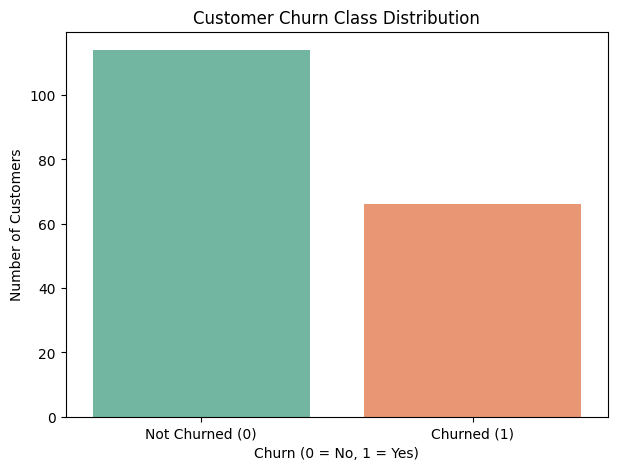


Class Distribution:
churn
0    114
1     66
Name: count, dtype: int64

Class Percentage:
churn
0    63.333333
1    36.666667
Name: proportion, dtype: float64


In [5]:

# Step 5: Class Distribution Plot

plt.figure(figsize=(7, 5))

sns.countplot(
    x='churn',
    data=df,
    hue='churn',
    palette='Set2',
    legend=False
)

plt.title('Customer Churn Class Distribution')
plt.xlabel('Churn (0 = No, 1 = Yes)')
plt.ylabel('Number of Customers')
plt.xticks([0, 1], ['Not Churned (0)', 'Churned (1)'])

plt.show()

print("\nClass Distribution:")
print(df['churn'].value_counts())

print("\nClass Percentage:")
print(df['churn'].value_counts(normalize=True) * 100)


In [6]:

# Step 6: Separate Features and Target

X = df.drop('churn', axis=1)
y = df['churn']

print("Features (X):")
display(X.head())

print("\nTarget (y):")
display(y.head())

print("\nFeature Shape:", X.shape)
print("Target Shape:", y.shape)


Features (X):


,tenure_months,monthly_charges,support_calls,online_security,contract_type_One year,contract_type_Two year
0,2,24.7,5,0,1,0
1,4,29.4,10,1,0,1
2,6,34.1,4,0,0,0
3,8,38.8,9,1,1,0
4,10,43.5,3,0,0,1



Target (y):


,churn
0,1
1,0
2,1
3,0
4,0



Feature Shape: (180, 6)
Target Shape: (180,)


In [7]:

# Step 8: Feature Scaling

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit on training data and transform
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed!")

print("\nScaled Training Data Shape:", X_train_scaled.shape)
print("Scaled Testing Data Shape:", X_test_scaled.shape)


NameError: name 'X_train' is not defined

In [8]:

# Step 7: Split Dataset into Training and Testing Sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training and Testing Split Completed!")

print("\nTraining Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())


Training and Testing Split Completed!

Training Features: (144, 6)
Testing Features: (36, 6)

Training Target: (144,)
Testing Target: (36,)

Training Class Distribution:
churn
0    91
1    53
Name: count, dtype: int64

Testing Class Distribution:
churn
0    23
1    13
Name: count, dtype: int64


In [9]:

# Step 8: Feature Scaling

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit on training data and transform
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed!")

print("\nScaled Training Data Shape:", X_train_scaled.shape)
print("Scaled Testing Data Shape:", X_test_scaled.shape)


Feature Scaling Completed!

Scaled Training Data Shape: (144, 6)
Scaled Testing Data Shape: (36, 6)


In [10]:

# Step 9: Train Logistic Regression Model

model = LogisticRegression(max_iter=1000)

# Train the model
model.fit(X_train_scaled, y_train)

print("Logistic Regression Model Trained Successfully!")

# Make predictions
y_pred = model.predict(X_test_scaled)

# Predict probabilities for ROC-AUC
y_prob = model.predict_proba(X_test_scaled)[:, 1]

print("\nModel Prediction Completed!")
print("\nActual Values:")
print(y_test.values)

print("\nPredicted Values:")
print(y_pred)


Logistic Regression Model Trained Successfully!

Model Prediction Completed!

Actual Values:
[0 1 1 0 0 0 1 0 1 1 0 1 1 1 0 0 0 0 1 0 0 0 0 0 1 0 0 1 0 0 1 0 0 0 1 0]

Predicted Values:
[0 1 1 0 0 0 1 0 1 1 0 1 0 1 0 0 0 0 1 0 0 0 0 0 1 0 0 1 0 0 1 0 0 0 0 0]


In [11]:

# Step 10: Model Evaluation

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Logistic Regression Model Evaluation")
print("------------------------------------")

print(f"Accuracy  : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")


Logistic Regression Model Evaluation
------------------------------------
Accuracy  : 0.9444 (94.44%)
Precision : 1.0000
Recall    : 0.8462
F1-Score  : 0.9167
ROC-AUC   : 1.0000


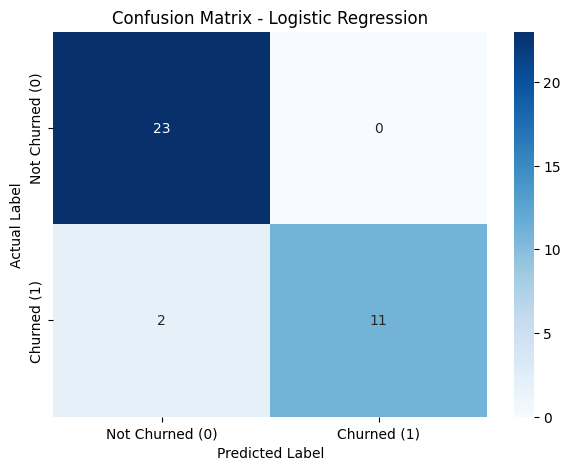

Confusion Matrix:
[[23  0]
 [ 2 11]]


In [12]:

# Step 11: Confusion Matrix Heatmap

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Churned (0)', 'Churned (1)'],
    yticklabels=['Not Churned (0)', 'Churned (1)']
)

plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

print("Confusion Matrix:")
print(cm)


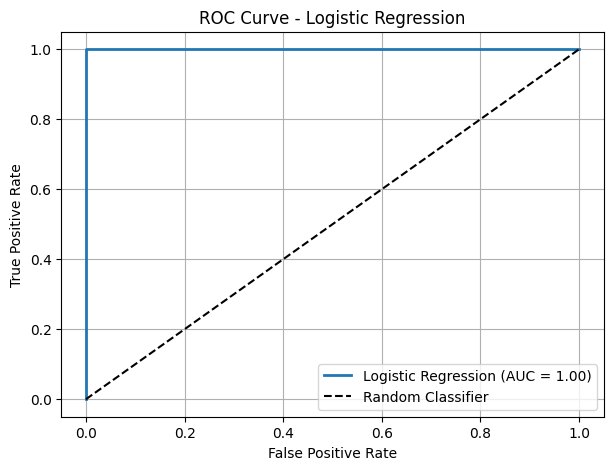

ROC-AUC Score: 1.0


In [13]:

# Step 12: ROC Curve

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f'Logistic Regression (AUC = {roc_auc:.2f})',
    linewidth=2
)

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Logistic Regression')

plt.legend()
plt.grid()
plt.show()

print("ROC-AUC Score:", roc_auc)


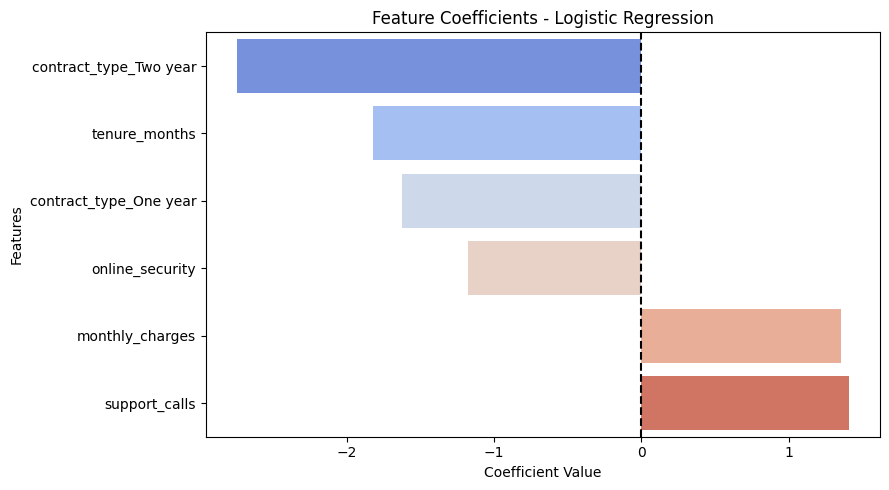

Feature Coefficients:


,Feature,Coefficient
5,contract_type_Two year,-2.748754
0,tenure_months,-1.820772
4,contract_type_One year,-1.623961
3,online_security,-1.176216
1,monthly_charges,1.353834
2,support_calls,1.411554


In [14]:

# Step 13: Feature Coefficient Bar Chart

coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0]
})

coefficients = coefficients.sort_values(
    by='Coefficient',
    ascending=True
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=coefficients,
    x='Coefficient',
    y='Feature',
    hue='Feature',
    palette='coolwarm',
    legend=False
)

plt.axvline(x=0, color='black', linestyle='--')

plt.title('Feature Coefficients - Logistic Regression')
plt.xlabel('Coefficient Value')
plt.ylabel('Features')

plt.tight_layout()
plt.show()

print("Feature Coefficients:")
display(coefficients)


In [15]:

# Step 14: Classification Report

print("Classification Report")
print("---------------------")

print(classification_report(
    y_test,
    y_pred,
    target_names=['Not Churned', 'Churned']
))


Classification Report
---------------------
              precision    recall  f1-score   support

 Not Churned       0.92      1.00      0.96        23
     Churned       1.00      0.85      0.92        13

    accuracy                           0.94        36
   macro avg       0.96      0.92      0.94        36
weighted avg       0.95      0.94      0.94        36

